# CAPTURE-24 activity recognition: MVP

Feature-based baselines for the 10-class and 4-class tasks of Chan et al., *Scientific Data* 2024 (doi:10.1038/s41597-024-03960-3): a dummy, a balanced random forest (A) and the forest with HMM smoothing (B).

## Setup

Imports, paths, seed, fold count, window length and label scheme names.

In [1]:
import json
import time
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from imblearn.ensemble import BalancedRandomForestClassifier
from joblib import Parallel, delayed
from sklearn.dummy import DummyClassifier
from sklearn.metrics import cohen_kappa_score, confusion_matrix, f1_score, matthews_corrcoef
from sklearn.model_selection import StratifiedGroupKFold

import features as F  # windowing and features; a module so joblib workers can import it and later rounds reuse it

T0 = time.time()
SEED = 42
N_FOLDS = 5
N_BOOT = 100
N_TREES = 300
HMM_FOLDS, HMM_TREES = 3, 50  # inner participant-grouped folds and trees per fold for the HMM emission matrix
N_JOBS = -1
LOAD_JOBS = 4  # participants processed in parallel; each holds about 1 GB

DATA, OUT = Path("data"), Path("outputs")
RAW = DATA / "capture24"
CACHE = DATA / f"features_w{F.WINSEC}s_v{F.FEATURE_VERSION}.parquet"
STATS_CACHE = DATA / f"participant_stats_w{F.WINSEC}s_v{F.FEATURE_VERSION}.parquet"

SCHEMES = {"10-class": "WillettsSpecific2018", "4-class": "Walmsley2020"}
CLASSES = {  # display order
    "10-class": ["sleep", "sitting", "standing", "household-chores", "manual-work",
                 "walking", "mixed-activity", "vehicle", "sports", "bicycling"],
    "4-class": ["sleep", "sedentary", "light", "moderate-vigorous"],
}
# Class codes are alphabetical, so a tied label vote resolves as pandas' mode() does in prepare_data.py.
CODES = {task: sorted(names) for task, names in CLASSES.items()}
DEV_IDS = [f"P{i:03d}" for i in range(1, 101)]  # derivation set; P101-P151 is the holdout
METRICS = ["macro_f1", "kappa", "mcc"]

PAPER_WINDOWS = {"all": 922_199, "P001-P100": 618_129, "P101-P151": 304_070}
PAPER = {  # holdout macro-F1 and kappa from the paper
    "10-class": {"Paper RF": (0.388, 0.514), "Paper RF + HMM": (0.486, 0.637)},
    "4-class": {"Paper RF": (0.711, 0.665), "Paper RF + HMM": (0.789, 0.772)},
}

INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
BLUE, ORANGE = "#2a78d6", "#eb6834"
CLASS_COLORS = dict(zip(CLASSES["10-class"], ["#52514e", "#c3c2b7", "#2a78d6", "#eb6834", "#1baf7a",
                                              "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]))
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "axes.axisbelow": True, "text.color": INK, "axes.labelcolor": "#52514e",
                     "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False, "figure.dpi": 110})
OUT.mkdir(exist_ok=True)

## Data

`capture24.zip` (CC BY 4.0, <https://doi.org/10.5287/bodleian:NGx0JOMP5>) goes in `data/`. Each participant is windowed and reduced to features on its own, so the 100 Hz signal is never held in memory at once; the result is cached.

In [2]:
if not RAW.exists():
    zipfile.ZipFile(DATA / "capture24.zip").extractall(DATA)
FILES = sorted(RAW.glob("P[0-9][0-9][0-9].csv.gz"))
print(len(FILES), "participant files;", "other files:", sorted(p.name for p in RAW.iterdir() if p not in FILES))
F.load_participant(FILES[0]).iloc[[0, 1, 3_000_000]]

151 participant files; other files: ['annotation-label-dictionary.csv', 'metadata.csv']


,time,x,y,z,annotation
0,2016-11-13 02:18:00.000,-0.46669,-0.533341,0.658472,7030 sleeping;MET 0.95
1,2016-11-13 02:18:00.010,-0.46669,-0.533341,0.658472,7030 sleeping;MET 0.95
3000000,2016-11-13 10:38:00.000,-0.92233,-0.346038,-0.302249,leisure;miscellaneous;5060 shopping miscellane...


In [3]:
def load_label_codes():
    """annotation string -> class code, per task. Fails if a scheme's classes are not the expected ones."""
    labels = pd.read_csv(RAW / "annotation-label-dictionary.csv", index_col="annotation", dtype="string")
    print("label schemes:", [c.removeprefix("label:") for c in labels.columns])
    codes = {}
    for task, scheme in SCHEMES.items():
        column = labels[f"label:{scheme}"]
        assert set(column) == set(CLASSES[task]), (scheme, sorted(set(column)))
        codes[task] = column.map(CODES[task].index).astype(int)
    return codes


LABEL_CODES = load_label_codes()
print(len(LABEL_CODES["10-class"]), "distinct annotations")

label schemes: ['WillettsSpecific2018', 'WillettsMET2018', 'DohertySpecific2018', 'Willetts2018', 'Doherty2018', 'Walmsley2020']
206 distinct annotations


In [4]:
def process_participant(path, label_codes):
    """One participant file -> (window table: ids, labels, features; raw-signal stats)."""
    raw = F.load_participant(path)
    time_, xyz = raw["time"].to_numpy(), raw[["x", "y", "z"]].to_numpy()
    annotation = raw["annotation"].cat  # codes: annotation id per sample, -1 where unlabelled
    class_of = {task: lookup[annotation.categories].to_numpy() for task, lookup in label_codes.items()}
    X, start, y, dropped = F.make_windows(time_, xyz, annotation.codes.to_numpy(), class_of)
    pid = path.name[:4]
    table = pd.concat([pd.DataFrame({"participant": pid, "window_start": start, **y}), F.extract_features(X)], axis=1)
    step_ms = np.diff(time_) / np.timedelta64(1, "ms")
    stats = {"participant": pid, "samples": len(raw), "hours": len(raw) / F.SAMPLE_RATE / 3600,
             "nan_share": np.isnan(xyz).any(axis=1).mean(), "unlabelled_share": raw["annotation"].isna().mean(),
             "steps_10ms": int((step_ms == 10).sum()), "steps_other_under_1s": int(((step_ms != 10) & (step_ms < 1000)).sum()),
             "steps_over_1s": int((step_ms >= 1000).sum()), "longest_step_s": step_ms.max() / 1000, **dropped}
    return table, stats


def load_windows():
    """Window table and per-participant stats for all participants, from cache when present."""
    if not (CACHE.exists() and STATS_CACHE.exists()):
        warnings.filterwarnings("ignore", message="A worker stopped")  # loky recycles workers as memory grows
        results = Parallel(n_jobs=LOAD_JOBS)(delayed(process_participant)(p, LABEL_CODES) for p in FILES)
        pd.concat([r[0] for r in results], ignore_index=True).to_parquet(CACHE)
        pd.DataFrame([r[1] for r in results]).to_parquet(STATS_CACHE)
    return pd.read_parquet(CACHE), pd.read_parquet(STATS_CACHE).set_index("participant")


windows, stats = load_windows()
IS_DEV = windows["participant"].isin(DEV_IDS).to_numpy()
print("participants with a timestamp step over 1 s:", int((stats["steps_over_1s"] > 0).sum()))
stats.describe().loc[["min", "50%", "max"]].T.map("{:,.2f}".format)

participants with a timestamp step over 1 s: 8


,min,50%,max
samples,"4,714,601.00","9,390,001.00","11,430,001.00"
hours,13.10,26.08,31.75
nan_share,0.00,0.00,0.00
unlabelled_share,0.17,0.32,0.69
steps_10ms,"4,714,600.00","9,390,000.00","11,430,000.00"
steps_other_under_1s,0.00,0.00,0.00
steps_over_1s,0.00,0.00,1.00
longest_step_s,0.01,0.01,"13,935.08"
n_bins,"4,715.00","9,391.00","11,431.00"
n_short,1.00,1.00,3.00


Window rule: 10 s bins from each participant's first sample; drop a bin if it has fewer than 1,000 samples, any NaN, or "unlabelled" as its most frequent annotation; label it with the most frequent class among its labelled samples, so a bin whose label changes partway is kept. The current `prepare_data.py` keeps any bin with one labelled sample, which gives 934,762 windows (+1.4%); the unlabelled-majority drop matches the paper's counts.

In [5]:
def window_counts():
    ours = {"all": len(windows), "P001-P100": int(IS_DEV.sum()), "P101-P151": int((~IS_DEV).sum())}
    table = pd.DataFrame({"ours": ours, "paper": PAPER_WINDOWS})
    table["diff %"] = (100 * (table["ours"] / table["paper"] - 1)).round(3)
    return table


COUNTS = window_counts()
assert (COUNTS["diff %"].abs() < 1).all(), "window counts differ from the paper by more than 1%"
print("bins dropped:", stats[["n_short", "n_nan", "n_unlabelled"]].sum().to_dict())
COUNTS

bins dropped: {'n_short': 163, 'n_nan': 0, 'n_unlabelled': 475823}


,ours,paper,diff %
all,922199,922199,0.0
P001-P100,618129,618129,0.0
P101-P151,304070,304070,0.0


## EDA

One participant's day with its labels, then the class balance of the two participant sets.

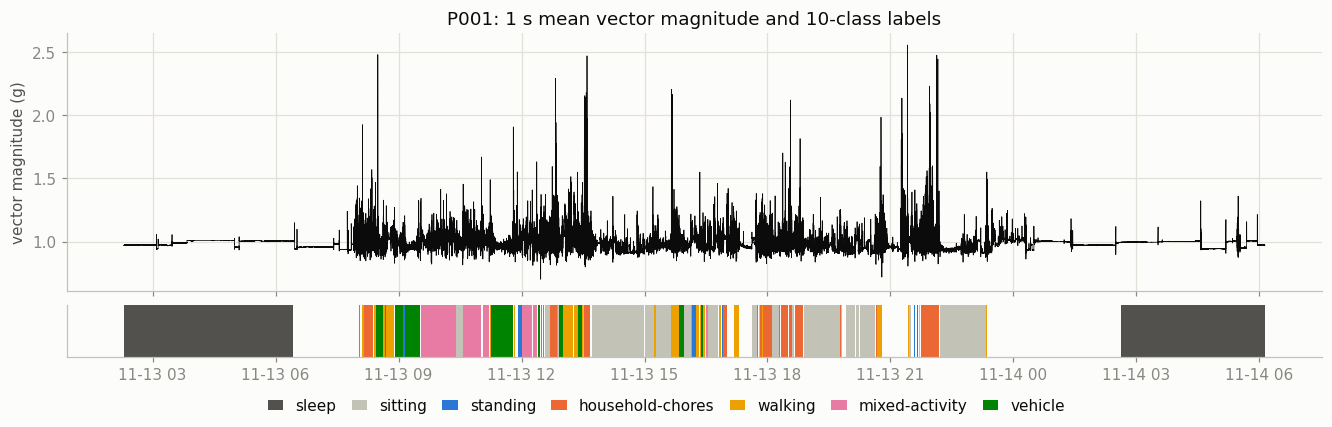

In [6]:
def plot_day(pid="P001"):
    """Per-second mean vector magnitude for one participant, with the 10-class labels as a band underneath."""
    raw = F.load_participant(RAW / f"{pid}.csv.gz")
    magnitude = pd.Series(np.linalg.norm(raw[["x", "y", "z"]].to_numpy(), axis=1), index=raw["time"]).resample("1s").mean()
    w = windows[windows["participant"] == pid]
    fig, (ax, band) = plt.subplots(2, 1, sharex=True, figsize=(12, 3.8), height_ratios=[5, 1], layout="constrained")
    ax.plot(magnitude.index, magnitude.to_numpy(), lw=0.5, color=INK)
    ax.set(ylabel="vector magnitude (g)", title=f"{pid}: 1 s mean vector magnitude and 10-class labels")
    for name in CLASSES["10-class"]:
        t = w.loc[w["10-class"] == CODES["10-class"].index(name), "window_start"]
        if len(t):
            band.bar(t, 1, width=pd.Timedelta(seconds=F.WINSEC), align="edge", color=CLASS_COLORS[name], label=name)
    band.set(yticks=[], ylim=(0, 1))
    band.grid(False)
    fig.legend(loc="outside lower center", ncols=10, handlelength=1, columnspacing=1)


plot_day()

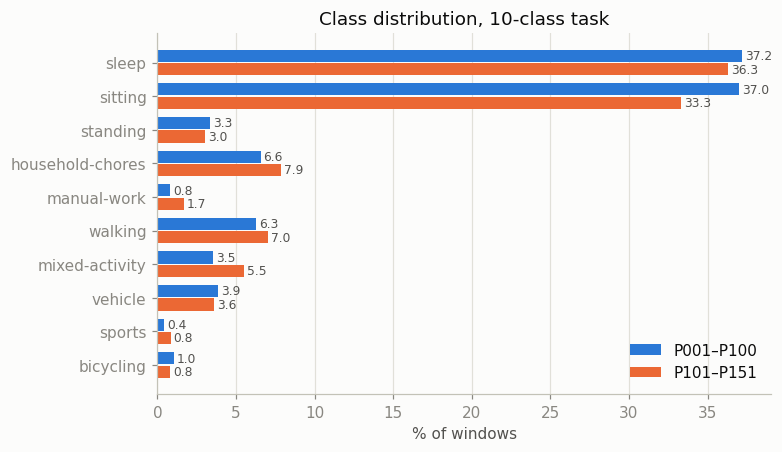

In [7]:
def plot_class_share():
    """Share of windows per class, derivation vs holdout."""
    names = CLASSES["10-class"]
    order = [CODES["10-class"].index(n) for n in names]
    share = lambda mask: np.bincount(windows.loc[mask, "10-class"], minlength=len(names))[order] / mask.sum() * 100
    _, ax = plt.subplots(figsize=(7, 4), layout="constrained")
    y = np.arange(len(names))
    for offset, mask, label, color in ((-0.2, IS_DEV, "P001–P100", BLUE), (0.2, ~IS_DEV, "P101–P151", ORANGE)):
        bars = ax.barh(y + offset, share(mask), height=0.36, color=color, label=label)
        ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8, color="#52514e")
    ax.set(yticks=y, yticklabels=names, xlabel="% of windows", title="Class distribution, 10-class task")
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.legend()


plot_class_share()

## Features

39 features per window, computed in `features.py` during the pass above. They follow the capture24 [feature list](https://github.com/OxWearables/capture24/blob/master/feature-list.md) (moments, quantiles, autocorrelation, spectrum and peaks of the vector magnitude) without its third dominant frequency, and add per-axis means and stds and inter-axis correlations. The model sees nothing else: no participant id, demographics or time.

In [8]:
X = windows[F.FEATURE_NAMES].to_numpy()
Y = {task: windows[task].to_numpy() for task in SCHEMES}
GROUPS = windows["participant"].to_numpy()
# A new sequence starts at each participant and wherever dropped windows leave a gap.
gap = windows["window_start"].diff().ne(pd.Timedelta(seconds=F.WINSEC)) | windows["participant"].ne(windows["participant"].shift())
SEQ = gap.cumsum().to_numpy()
assert np.isfinite(X).all()
print(X.shape, "| sequences:", SEQ.max())
windows[F.FEATURE_NAMES].describe().loc[["mean", "std", "min", "max"]].T.round(3)

(922199, 39) | sequences: 13052


,mean,std,min,max
avg,0.011,0.050,-0.164,1.758
std,0.064,0.098,0.000,0.965
skew,0.526,1.239,-16.312,28.608
kurt,5.431,13.388,-1.867,876.710
min,-0.178,0.217,-0.981,0.699
q25,-0.021,0.047,-0.664,1.724
med,0.005,0.041,-0.314,2.000
q75,0.037,0.096,-0.159,2.000
max,0.317,0.476,-0.153,2.000
x_mean,-0.152,0.607,-1.831,1.196


## Models

Metrics, the HMM (Viterbi and forward-backward) and the fit for one train/test split. Metrics take a confusion matrix, so the participant bootstrap can sum per-participant matrices.

In [9]:
def metrics_from_cm(cm):
    """Confusion matrix (rows = truth) -> macro-F1, Cohen's kappa, multiclass MCC and per-class F1."""
    cm = np.asarray(cm, dtype=float)
    n, true, pred, hit = cm.sum(), cm.sum(axis=1), cm.sum(axis=0), np.diag(cm)
    seen = true + pred > 0  # like sklearn, average F1 over classes that occur in truth or prediction
    f1 = np.where(seen, 2 * hit / np.where(seen, true + pred, 1), np.nan)
    chance = true @ pred
    mcc_den = np.sqrt((n**2 - pred @ pred) * (n**2 - true @ true))
    return {"macro_f1": float(np.nanmean(f1)),
            "kappa": float((n * hit.sum() - chance) / (n**2 - chance)),
            "mcc": float((n * hit.sum() - chance) / mcc_den) if mcc_den else 0.0,
            "per_class_f1": f1.tolist()}


def test_metrics():
    # Hand-checked: F1 = 0.8 and 2/3; accuracy 0.75 vs chance 0.5 -> kappa 0.5; MCC = 2 / sqrt(12).
    m = metrics_from_cm(confusion_matrix([0, 0, 1, 1], [0, 0, 1, 0]))
    assert np.allclose([m["macro_f1"], m["kappa"], m["mcc"]], [(0.8 + 2 / 3) / 2, 0.5, 2 / 12**0.5])
    rng = np.random.default_rng(SEED)
    t, p = rng.integers(0, 10, 5000), rng.integers(0, 10, 5000)
    m = metrics_from_cm(confusion_matrix(t, p))
    assert np.allclose([m["macro_f1"], m["kappa"], m["mcc"]],
                       [f1_score(t, p, average="macro"), cohen_kappa_score(t, p), matthews_corrcoef(t, p)])


test_metrics()

In [10]:
TINY = 1e-16  # keeps log(0) finite


def viterbi(obs, prior, trans, emit):
    """Most likely state path for observed symbols `obs`; emit[state, symbol], trans[from, to]."""
    log_trans, log_emit = np.log(trans + TINY), np.log(emit + TINY)
    score = np.log(prior + TINY) + log_emit[:, obs[0]]
    back = np.zeros((len(obs), len(prior)), dtype=int)
    for t in range(1, len(obs)):
        step = score[:, None] + log_trans  # step[i, j]: best path ending in i, then moving to j
        back[t] = step.argmax(axis=0)
        score = step.max(axis=0) + log_emit[:, obs[t]]
    path = np.empty(len(obs), dtype=int)
    path[-1] = score.argmax()
    for t in range(len(obs) - 1, 0, -1):
        path[t - 1] = back[t, path[t]]
    return path


def posterior(obs, prior, trans, emit):
    """P(state at t | all observations) by scaled forward-backward; rows sum to 1."""
    lik = emit[:, obs].T + TINY
    alpha, beta = np.empty_like(lik), np.ones_like(lik)
    a = prior * lik[0]
    alpha[0] = a / a.sum()
    for t in range(1, len(obs)):
        a = (alpha[t - 1] @ trans) * lik[t]
        alpha[t] = a / a.sum()
    for t in range(len(obs) - 2, -1, -1):
        b = trans @ (lik[t + 1] * beta[t + 1])
        beta[t] = b / b.sum()
    gamma = alpha * beta
    return gamma / gamma.sum(axis=1, keepdims=True)


def test_hmm():
    # Sticky 2-state chain. One odd symbol costs 1/4 (0.2 vs 0.8); switching there and back costs 1/81, so stay.
    # Three odd symbols cost 1/64; one switch costs 1/9, so switch.
    hmm = dict(prior=np.array([0.5, 0.5]), trans=np.array([[0.9, 0.1], [0.1, 0.9]]), emit=np.array([[0.8, 0.2], [0.2, 0.8]]))
    assert viterbi(np.array([0, 0, 1, 0, 0]), **hmm).tolist() == [0, 0, 0, 0, 0]
    assert viterbi(np.array([0, 0, 1, 1, 1]), **hmm).tolist() == [0, 0, 1, 1, 1]
    post = posterior(np.array([0, 0, 1, 1, 1]), **hmm)
    assert np.allclose(post.sum(axis=1), 1) and post.argmax(axis=1).tolist() == [0, 0, 1, 1, 1]
    # Single observation: Bayes' rule gives 0.8 / (0.8 + 0.2).
    assert np.allclose(posterior(np.array([0]), **hmm), [[0.8, 0.2]])


test_hmm()

In [11]:
def fit_hmm(y, oof_proba, seq, k):
    """HMM over true classes, from training rows only: class prior, transitions between consecutive
    windows of a sequence, and emission P(forest output | true class) from out-of-fold probabilities."""
    follows = seq[1:] == seq[:-1]
    trans = np.zeros((k, k))
    np.add.at(trans, (y[:-1][follows], y[1:][follows]), 1)
    return {"prior": np.bincount(y, minlength=k) / len(y),
            "trans": trans / trans.sum(axis=1, keepdims=True),
            "emit": np.stack([oof_proba[y == c].mean(axis=0) for c in range(k)])}


def smooth(pred, seq, hmm):
    """Decode each gap-free sequence on its own. Returns the Viterbi path and the posterior."""
    path, post = np.empty_like(pred), np.empty((len(pred), len(hmm["prior"])))
    edges = np.flatnonzero(np.r_[True, seq[1:] != seq[:-1], True])
    for a, b in zip(edges[:-1], edges[1:]):
        path[a:b] = viterbi(pred[a:b], **hmm)
        post[a:b] = posterior(pred[a:b], **hmm)
    return path, post


def fit_forest(rows, y, n_trees=N_TREES):
    forest = BalancedRandomForestClassifier(
        n_estimators=n_trees, sampling_strategy="not minority", replacement=True, bootstrap=True,
        n_jobs=N_JOBS, random_state=SEED).fit(X[rows], y[rows])
    assert forest.classes_.tolist() == list(range(y.max() + 1))
    return forest


def out_of_fold_proba(train, y):
    """Forest probabilities for each training row, from a forest that never saw that row's participant."""
    proba = np.empty((len(train), y.max() + 1))
    folds = StratifiedGroupKFold(HMM_FOLDS, shuffle=True, random_state=SEED).split(train, y[train], GROUPS[train])
    for fit, held in folds:
        proba[held] = fit_forest(train[fit], y, HMM_TREES).predict_proba(X[train[held]])
    return proba


def run_split(task, train, test):
    """Fit Dummy, A and B on `train` rows only. Returns test predictions, test probabilities and the forest."""
    y, k = Y[task], len(CODES[task])
    forest = fit_forest(train, y)
    hmm = fit_hmm(y[train], out_of_fold_proba(train, y), SEQ[train], k)
    proba = forest.predict_proba(X[test])
    pred_a = proba.argmax(axis=1)
    pred_b, post = smooth(pred_a, SEQ[test], hmm)
    dummy = DummyClassifier(strategy="most_frequent").fit(X[train], y[train])
    return {"Dummy": dummy.predict(X[test]), "A": pred_a, "B": pred_b}, {"A": proba, "B": post}, forest

## Evaluation

5-fold participant-grouped CV on P001–P100, then one fit on all of P001–P100 scored once on P101–P151. Baseline A is imblearn's `BalancedRandomForestClassifier` with 300 trees. The HMM's prior, transition matrix and emission matrix come from the training participants of each fit; the emission matrix uses out-of-fold probabilities from an inner 3-fold participant-grouped split with 50-tree forests, because imblearn's out-of-bag estimate covers only the few windows each tree sampled.

Label caveat: labels come from wearable-camera frames taken every 20–40 s plus sleep diaries, and the paper says annotators sometimes guessed. Household-chores, standing, walking, manual-work and mixed-activity overlap in real life, so part of the error is label noise.

In [12]:
def cv_folds(task):
    """Participant-grouped (train, valid) row indices within P001-P100."""
    dev = np.flatnonzero(IS_DEV)
    for train, valid in StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED).split(dev, Y[task][dev], GROUPS[dev]):
        assert not set(GROUPS[dev[train]]) & set(GROUPS[dev[valid]])
        yield dev[train], dev[valid]


def score_rows(task, rows, preds, **tags):
    """One row of metrics per model in `preds`."""
    k = len(CODES[task])
    scores = {model: metrics_from_cm(confusion_matrix(Y[task][rows], pred, labels=range(k))) for model, pred in preds.items()}
    return [{"task": task, "model": model, **tags, **{m: s[m] for m in METRICS}} for model, s in scores.items()]


def cross_validate(task):
    """Per-fold metrics for each model."""
    return [row for fold, (train, valid) in enumerate(cv_folds(task))
            for row in score_rows(task, valid, run_split(task, train, valid)[0], fold=fold)]


cv = pd.DataFrame([row for task in SCHEMES for row in cross_validate(task)])
CV = cv.groupby(["task", "model"])[METRICS].agg(["mean", "std"])
CV.round(3)

macro_f1         kappa           mcc       
                   mean    std   mean    std   mean    std
task     model                                            
10-class A        0.406  0.017  0.535  0.014  0.542  0.016
         B        0.514  0.033  0.712  0.013  0.715  0.013
         Dummy    0.055  0.003  0.000  0.000  0.000  0.000
4-class  A        0.708  0.017  0.673  0.020  0.674  0.020
         B        0.821  0.018  0.825  0.020  0.826  0.020
         Dummy    0.145  0.007  0.000  0.000  0.000  0.000

In [13]:
DEV, TEST = np.flatnonzero(IS_DEV), np.flatnonzero(~IS_DEV)
assert not set(GROUPS[DEV]) & set(GROUPS[TEST])
HOLDOUT = {task: run_split(task, DEV, TEST) for task in SCHEMES}  # the only use of P101-P151

Holdout intervals are 95% percentile bootstraps (n = 100) over test participants, because windows from one person are correlated. The paper says only "bootstrapping (n=100)"; its repo's `eval.py` resamples participants and reports a basic bootstrap interval.

In [14]:
def participant_cms(y_true, y_pred, groups, k):
    """One confusion matrix per participant, shape (participants, k, k)."""
    g = pd.factorize(groups)[0]
    cms = np.zeros((g.max() + 1, k, k))
    np.add.at(cms, (g, y_true, y_pred), 1)
    return cms


def score_holdout(task, pred):
    """Point metrics and bootstrap CI, resampling participants."""
    cms = participant_cms(Y[task][TEST], pred, GROUPS[TEST], len(CODES[task]))
    draws = np.random.default_rng(SEED).integers(0, len(cms), (N_BOOT, len(cms)))
    boots = pd.DataFrame([metrics_from_cm(cms[d].sum(axis=0)) for d in draws])[METRICS]
    point = metrics_from_cm(cms.sum(axis=0))
    lo, hi = boots.quantile(0.025), boots.quantile(0.975)
    return {**{m: {"value": point[m], "ci": [lo[m], hi[m]]} for m in METRICS},
            "per_class_f1": dict(zip(CODES[task], point["per_class_f1"])), "cm": cms.sum(axis=0)}


SCORES = {task: {model: score_holdout(task, pred) for model, pred in HOLDOUT[task][0].items()} for task in SCHEMES}

In [15]:
def results_table():
    """Rows: models and paper references. Columns: task x metric x (CV mean ± std, holdout [95% CI])."""
    cells = {}
    for task in SCHEMES:
        for model in ("Dummy", "A", "B"):
            for m in METRICS:
                mean, std = CV.loc[(task, model), m]
                h = SCORES[task][model][m]
                cells[task, m, "CV", model] = f"{mean:.3f} ± {std:.3f}"
                cells[task, m, "holdout", model] = f"{h['value']:.3f} [{h['ci'][0]:.3f}, {h['ci'][1]:.3f}]"
        for model, (f1, kappa) in PAPER[task].items():
            cells[task, "macro_f1", "holdout", model] = f"{f1:.3f}"
            cells[task, "kappa", "holdout", model] = f"{kappa:.3f}"
    table = pd.Series(cells).unstack(level=[0, 1, 2]).fillna("–")
    columns = [(t, m, s) for t in SCHEMES for m in METRICS for s in ("CV", "holdout")]
    return table.loc[["Dummy", "A", "B", "Paper RF", "Paper RF + HMM"], columns]


RESULTS = results_table()
RESULTS.rename(index={"A": "A: balanced RF", "B": "B: A + HMM"})

10-class                                       \
                     macro_f1                                kappa   
                           CV               holdout             CV   
Dummy           0.055 ± 0.003  0.053 [0.050, 0.055]  0.000 ± 0.000   
A: balanced RF  0.406 ± 0.017  0.415 [0.387, 0.438]  0.535 ± 0.014   
B: A + HMM      0.514 ± 0.033  0.532 [0.489, 0.568]  0.712 ± 0.013   
Paper RF                    –                 0.388              –   
Paper RF + HMM              –                 0.486              –   

                                                                           \
                                                mcc                         
                             holdout             CV               holdout   
Dummy           0.000 [0.000, 0.000]  0.000 ± 0.000  0.000 [0.000, 0.000]   
A: balanced RF  0.530 [0.503, 0.552]  0.542 ± 0.016  0.535 [0.508, 0.557]   
B: A + HMM      0.711 [0.670, 0.743]  0.715 ± 0.013  0.714 [0.676, 0.746]   
Paper RF                       0.514              –                     –   
Paper RF + HMM                 0.637              –                     –   

                      4-class                                       \
                     macro_f1                                kappa   
                           CV               holdout             CV   
Dummy           0.145 ± 0.007  0.136 [0.128, 0.146]  0.000 ± 0.000   
A: balanced RF  0.708 ± 0.017  0.724 [0.701, 0.747]  0.673 ± 0.020   
B: A + HMM      0.821 ± 0.018  0.829 [0.801, 0.857]  0.825 ± 0.020   
Paper RF                    –                 0.711              –   
Paper RF + HMM              –                 0.789              –   

                                                                           
                                                mcc                        
                             holdout             CV               holdout  
Dummy           0.000 [0.000, 0.000]  0.000 ± 0.000  0.000 [0.000, 0.000]  
A: balanced RF  0.681 [0.651, 0.707]  0.674 ± 0.020  0.682 [0.653, 0.708]  
B: A + HMM      0.822 [0.789, 0.856]  0.826 ± 0.020  0.823 [0.791, 0.856]  
Paper RF                       0.665              –                     –  
Paper RF + HMM                 0.772              –                     –

B is above the paper's RF + HMM on both tasks, which calls for a leakage check. The next cell reruns CV fold 0 the paper's way (its 30 features, imblearn's out-of-bag emissions, a uniform prior, one sequence per participant) next to our pipeline on the same fold. Fold 0 is harder than the holdout, so compare the two columns with each other.

In [16]:
def paper_style_fold0(task):
    """Metrics on CV fold 0 for the paper's pipeline, next to ours on the same fold."""
    y, k = Y[task], len(CODES[task])
    train, valid = next(cv_folds(task))
    cols = [i for i, name in enumerate(F.FEATURE_NAMES) if not name.startswith(("x_", "y_", "z_", "corr_"))]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # imblearn warns that some windows have no out-of-bag score
        forest = BalancedRandomForestClassifier(
            n_estimators=N_TREES, sampling_strategy="not minority", replacement=True, bootstrap=True,
            oob_score=True, n_jobs=N_JOBS, random_state=SEED).fit(X[train][:, cols], y[train])
    per_participant = pd.factorize(GROUPS)[0]
    hmm = fit_hmm(y[train], forest.oob_decision_function_, per_participant[train], k) | {"prior": np.full(k, 1 / k)}
    pred = forest.predict(X[valid][:, cols])
    return score_rows(task, valid, {"A": pred, "B": smooth(pred, per_participant[valid], hmm)[0]}, pipeline="paper-style")


def fold0_comparison():
    ours = cv[(cv["fold"] == 0) & (cv["model"] != "Dummy")].assign(pipeline="ours")
    paper_style = pd.DataFrame([row for task in SCHEMES for row in paper_style_fold0(task)])
    both = pd.concat([paper_style, ours]).set_index(["task", "model", "pipeline"])[["macro_f1", "kappa"]]
    return both.unstack("pipeline").round(3)


fold0_comparison()

macro_f1              kappa            
pipeline           ours paper-style   ours paper-style
task     model                                        
10-class A        0.379       0.352  0.522       0.486
         B        0.465       0.450  0.691       0.612
4-class  A        0.703       0.680  0.663       0.606
         B        0.809       0.794  0.816       0.763

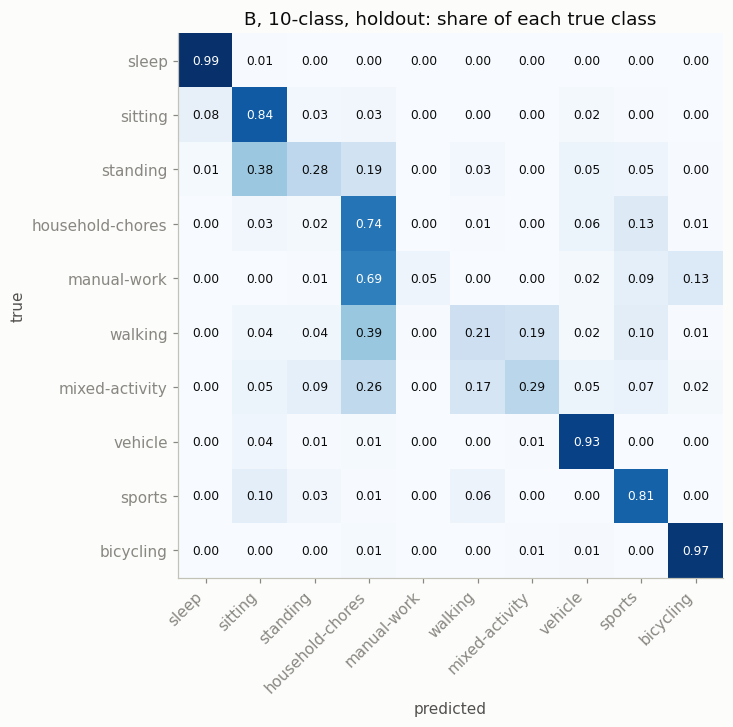

In [17]:
def plot_confusion(task="10-class", model="B"):
    """Row-normalised holdout confusion matrix."""
    order = [CODES[task].index(n) for n in CLASSES[task]]
    cm = SCORES[task][model]["cm"][np.ix_(order, order)]
    cm = cm / cm.sum(axis=1, keepdims=True)
    _, ax = plt.subplots(figsize=(7.5, 6.5), layout="constrained")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(order)):
        for j in range(len(order)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 0.5 else INK)
    ax.set(xticks=range(len(order)), yticks=range(len(order)), yticklabels=CLASSES[task], xlabel="predicted", ylabel="true",
           title=f"{model}, {task}, holdout: share of each true class")
    ax.set_xticklabels(CLASSES[task], rotation=45, ha="right")
    ax.grid(False)


plot_confusion()

In [18]:
def per_class_f1(task="10-class"):
    """Holdout F1 per class before and after the HMM."""
    table = pd.DataFrame({m: SCORES[task][m]["per_class_f1"] for m in ("A", "B")}).loc[CLASSES[task]]
    table["B - A"] = table["B"] - table["A"]
    return table.round(3)


per_class_f1()

,A,B,B - A
sleep,0.908,0.962,0.054
sitting,0.687,0.876,0.189
standing,0.176,0.293,0.117
household-chores,0.416,0.557,0.141
manual-work,0.059,0.092,0.032
walking,0.331,0.309,-0.022
mixed-activity,0.259,0.373,0.114
vehicle,0.423,0.772,0.349
sports,0.317,0.330,0.013
bicycling,0.570,0.757,0.187


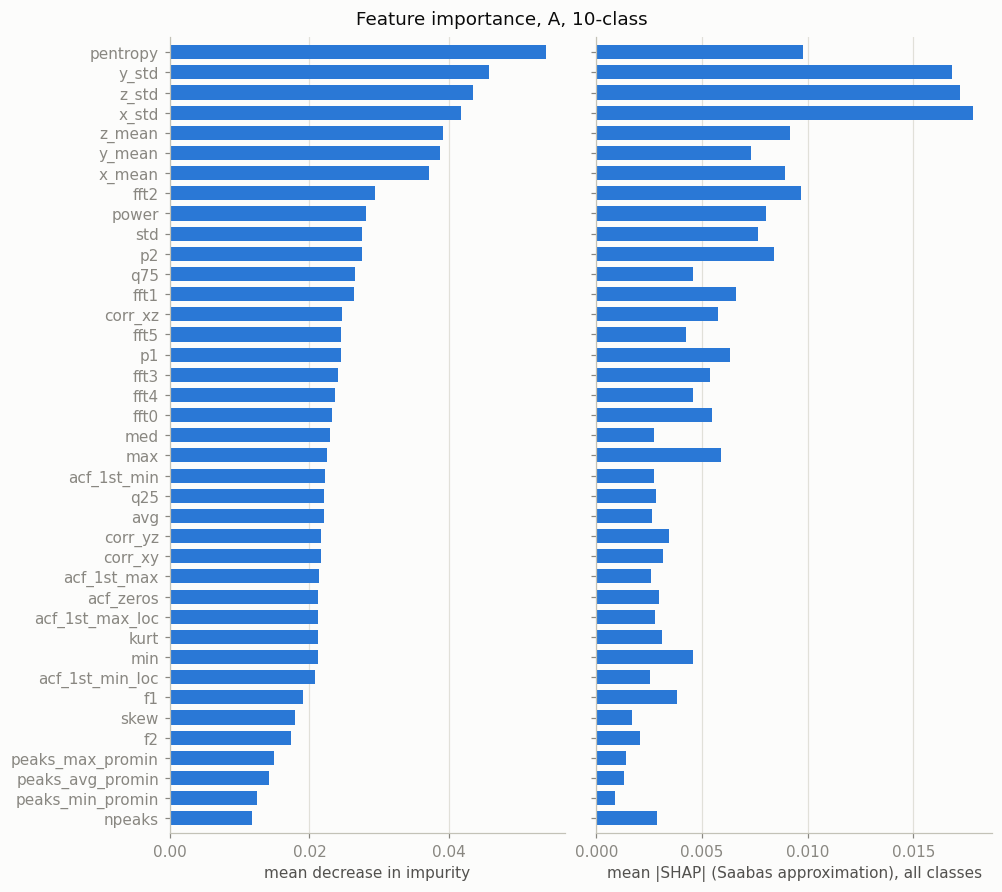

In [19]:
def plot_importance(task="10-class", n_shap=5000):
    """Impurity importance and mean |SHAP| of each feature in the final forest."""
    forest = HOLDOUT[task][2]
    rows = np.random.default_rng(SEED).choice(DEV, n_shap, replace=False)
    # approximate=True (Saabas): exact TreeSHAP takes about 1.7 s per window on trees this deep.
    shap_values = shap.TreeExplainer(forest).shap_values(X[rows], approximate=True, check_additivity=False)
    table = pd.DataFrame({"mean decrease in impurity": forest.feature_importances_,
                          "mean |SHAP| (Saabas approximation), all classes": np.abs(shap_values).mean(axis=(0, 2))},
                         index=F.FEATURE_NAMES).sort_values("mean decrease in impurity")
    fig, axes = plt.subplots(1, 2, figsize=(9, 8), sharey=True, layout="constrained")
    for ax, column in zip(axes, table):
        ax.barh(table.index, table[column], color=BLUE, height=0.7)
        ax.set(xlabel=column)
        ax.grid(axis="y", visible=False)
        ax.margins(y=0.01)
        ax.locator_params(axis="x", nbins=5)
    fig.suptitle(f"Feature importance, A, {task}")


plot_importance()

## Holdout predictions

The model with the higher CV macro-F1 on the 10-class task is saved; the 4-class task is in `results.json` only. For B, `y_pred` is the Viterbi path and the probabilities are the HMM posterior, so their argmax can differ from `y_pred`. Probability columns are in alphabetical class order, recorded in `results.json`; the `.npy` holds full precision.

In [20]:
def save_holdout(task="10-class"):
    """Write per-window holdout predictions and probabilities; return the model name."""
    best = CV.loc[task].loc[["A", "B"], ("macro_f1", "mean")].idxmax()
    preds, probas, _ = HOLDOUT[task]
    names, proba = np.array(CODES[task]), probas[best]
    assert len(proba) == len(TEST) == COUNTS.loc["P101-P151", "ours"]
    assert proba.min() >= 0 and proba.max() <= 1 and np.abs(proba.sum(axis=1) - 1).max() < 1e-6
    table = windows.loc[TEST, ["participant", "window_start"]].assign(y_true=names[Y[task][TEST]], y_pred=names[preds[best]])
    table = pd.concat([table.reset_index(drop=True), pd.DataFrame(proba, columns=[f"p_{n}" for n in names])], axis=1)
    table.to_csv(OUT / "holdout_predictions.csv", index=False)
    np.save(OUT / "holdout_proba.npy", proba)
    print(f"saved {best}: {len(table):,} rows; argmax(proba) == y_pred for {(proba.argmax(axis=1) == preds[best]).mean():.1%}")
    return best


BEST = save_holdout()

saved B: 304,070 rows; argmax(proba) == y_pred for 99.1%


In [21]:
def save_results():
    results = {"config": {"seed": SEED, "n_folds": N_FOLDS, "n_boot": N_BOOT, "n_trees": N_TREES, "winsec": F.WINSEC,
                          "n_features": len(F.FEATURE_NAMES), "schemes": SCHEMES, "saved_model": BEST, "proba_columns": CODES["10-class"]},
               "windows": COUNTS.to_dict(), "paper": PAPER, "tasks": {}}
    for task in SCHEMES:
        results["tasks"][task] = {
            model: {"cv": {m: dict(zip(("mean", "std"), CV.loc[(task, model), m])) for m in METRICS},
                    "holdout": {m: SCORES[task][model][m] for m in METRICS},
                    "holdout_per_class_f1": SCORES[task][model]["per_class_f1"]}
            for model in ("Dummy", "A", "B")}
    (OUT / "results.json").write_text(json.dumps(results, indent=2))


save_results()
print(f"run time: {(time.time() - T0) / 60:.1f} min")

run time: 8.5 min


## Next steps

Out of scope this round, ordered by expected gain toward 10-class macro-F1 0.576:

1. Self-supervised pretrained encoder (OxWearables `ssl-wearables`) fine-tuned on raw windows, plus the HMM.
2. CNN or RNN on raw windows, plus the HMM (the paper's best: CNN + HMM).
3. Ensemble of the feature model and the deep model before smoothing.
4. Hyperparameter search for the forest or LightGBM, and HMM emissions from participant-grouped out-of-fold probabilities.
5. Label-noise and boundary-aware training (soft labels near annotation changes).
6. Time-of-day features, as a separately labelled experiment.